In [40]:
!pip install yfinance

#Task 1 Data Preparation and Feature Engineering

**1.1 Ticker selection and data acquisition**

In [41]:
import os, json
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
import yfinance as yf

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 42
START, END = "2021-01-01", "2025-01-01"
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("pandas", pd.__version__, "| numpy", np.__version__)
print("yfinance", yf.__version__, "| scikit-learn", sklearn.__version__)
print("scipy", scipy.__version__)

pandas 2.2.3 | numpy 2.4.6
yfinance 0.2.66 | scikit-learn 1.6.1
scipy 1.16.3


In [42]:
import zipfile, glob
# Colab or the browser may rename repeat uploads, e.g. "data (3).zip", so accept any data*.zip
snapshots = sorted(glob.glob("data*.zip"))
if snapshots:
    zipfile.ZipFile(snapshots[0]).extractall("data")   # overwrites any older files in data/
    print("Unzipped", snapshots[0])
USE_CACHE = os.path.exists("data/close.csv.gz") and os.path.exists("data/metadata.json")
print("Using saved data snapshot:", USE_CACHE)

Unzipped data.zip
Using saved data snapshot: True


In [43]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

if USE_CACHE and os.path.exists("data/sp500_constituents.csv"):
    # reuse the saved constituent list and its original retrieval date
    sp500 = pd.read_csv("data/sp500_constituents.csv")
    retrieved = json.load(open("data/metadata.json"))["tickers_retrieved"]
else:
    sp500 = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})[0]
    # Yahoo writes BRK-B where Wikipedia writes BRK.B
    sp500["yahoo_ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)
    retrieved = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    sp500.to_csv("data/sp500_constituents.csv", index=False)

tickers = sorted(sp500["yahoo_ticker"].unique())
print(len(tickers), "tickers retrieved on", retrieved)
sp500.head()

503 tickers retrieved on 2026-11-25 04:12 UTC


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded,yahoo_ticker
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902,MMM
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916,AOS
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888,ABT
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888),ABBV
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989,ACN


In [44]:
if USE_CACHE:
    # the saved snapshot uses exactly the same prices
    def load(name):
        return pd.read_csv(f"data/{name}.csv.gz", index_col=0, parse_dates=True)
    adj, close, vol = load("adj_close"), load("close"), load("volume")
    splits, divs = load("splits"), load("dividends")
    meta = json.load(open("data/metadata.json"))
    print("Loaded snapshot downloaded on", meta["prices_retrieved"], "UTC")
else:
    raw = yf.download(tickers + ["^GSPC"], start=START, end=END,
                      auto_adjust=False, actions=True, progress=False)

    adj, close, vol = raw["Adj Close"], raw["Close"], raw["Volume"]
    splits, divs = raw["Stock Splits"], raw["Dividends"]

    for name, table in [("adj_close", adj), ("close", close), ("volume", vol),
                        ("splits", splits), ("dividends", divs)]:
        table.to_csv(f"data/{name}.csv.gz")

    meta = {"tickers_source": url, "tickers_retrieved": retrieved,
            "prices_source": "Yahoo Finance via yfinance " + yf.__version__,
            "prices_retrieved": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M"),
            "start": START, "end_exclusive": END}
    json.dump(meta, open("data/metadata.json", "w"), indent=2)
print(close.shape, close.index.min().date(), close.index.max().date())

Loaded snapshot downloaded on 2026-11-25 04:13 UTC
(1005, 504) 2021-01-04 2024-12-31


**1.2 Data validation and alignment**

In [45]:
bench = adj["^GSPC"].dropna()
calendar = bench.index
print("Trading sessions:", len(calendar))
print("Duplicate dates:", close.index.duplicated().sum())

rows = []
for t in tickers:
    if t not in close.columns or close[t].notna().sum() == 0:
        rows.append({"ticker": t, "reason": "no data returned by Yahoo"})
        continue
    a = adj[t].reindex(calendar)
    c = close[t].reindex(calendar)
    v = vol[t].reindex(calendar)
    reason = ""
    if a.isna().any() or c.isna().any() or v.isna().any():
        reason = f"incomplete history ({int(c.isna().sum())} sessions missing)"
    elif (a <= 0).any() or (c <= 0).any():
        reason = "zero or negative price"
    elif (v <= 0).any():
        reason = "zero or negative volume"
    rows.append({"ticker": t, "first_date": c.first_valid_index(),
                 "reason": reason})

log = pd.DataFrame(rows).set_index("ticker")
keep = log.index[log["reason"] == ""].tolist()
print("Kept:", len(keep), "| dropped:", len(tickers) - len(keep))
log[log["reason"] != ""]

Trading sessions: 1005
Duplicate dates: 0
Kept: 486 | dropped: 17


,first_date,reason
ticker,,
APP,2021-04-15,incomplete history (70 sessions missing)
CEG,2022-01-19,incomplete history (263 sessions missing)
COIN,2021-04-14,incomplete history (69 sessions missing)
EXE,2021-02-10,incomplete history (26 sessions missing)
FDXF,NaT,no data returned by Yahoo
FERG,2021-01-04,zero or negative volume
GEHC,2022-12-15,incomplete history (492 sessions missing)
GEV,2024-03-27,incomplete history (812 sessions missing)
HONA,NaT,no data returned by Yahoo


In [46]:
# where the two zero-volume shares have zero-volume sessions
for t in ["FERG", "SW"]:
    v = vol[t].reindex(calendar)
    zero_days = v.index[v == 0]
    print(t, "zero-volume sessions:", len(zero_days),
          "| first:", zero_days[0].date(), "| last:", zero_days[-1].date())

FERG zero-volume sessions: 27 | first: 2021-01-07 | last: 2021-03-05
SW zero-volume sessions: 424 | first: 2021-01-05 | last: 2024-07-05


**Corporate actions: splits and dividends**

If Close were not adjusted for splits, a 4-for-1 split would look like a 75% fall on the split date. For each split among retained shares, the actual Close change on the split day is compared with the change an unadjusted price would show. Adjusted Close is used for returns because it also removes dividend drops; ^GSPC is a price index, so its Adjusted Close should equal its Close.

In [47]:
checks = []
for t in keep:
    s = splits[t].reindex(calendar).fillna(0)
    c = close[t].reindex(calendar)
    for d in s.index[s != 0]:
        i = calendar.get_loc(d)
        if i == 0:
            continue
        change = c.iloc[i] / c.iloc[i - 1] - 1
        checks.append({"ticker": t, "date": d.date(), "ratio": s[d],
                       "close_change_that_day": round(change, 3),
                       "change_if_uncorrected": round(1 / s[d] - 1, 3)})
split_check = pd.DataFrame(checks)
whole = split_check[split_check["ratio"] >= 2]          # true share splits (2-for-1 or more)
print(len(split_check), "split events among retained shares;", len(whole), "are 2-for-1 or larger")
print("Largest absolute Close change on a 2-for-1+ split day:",
      whole["close_change_that_day"].abs().max())
print("Smallest change an unadjusted price would have shown:",
      whole["change_if_uncorrected"].abs().min())

gap = (adj["^GSPC"] - close["^GSPC"]).abs().max()
print("Benchmark: largest gap between Adj Close and Close =", gap)
paying = int((divs[keep].reindex(calendar).fillna(0) != 0).any().sum())
print("Retained shares that paid a dividend in the period:", paying)
split_check.to_csv("outputs/split_check.csv", index=False)
whole.sort_values("close_change_that_day", key=abs, ascending=False).head(10)

61 split events among retained shares; 38 are 2-for-1 or larger
Largest absolute Close change on a 2-for-1+ split day: 0.074
Smallest change an unadjusted price would have shown: 0.5
Benchmark: largest gap between Adj Close and Close = 0.0
Retained shares that paid a dividend in the period: 392


,ticker,date,ratio,close_change_that_day,change_if_uncorrected
18,DXCM,2022-06-13,4.0,-0.074,-0.750
52,TECH,2022-11-30,4.0,0.039,-0.750
11,CSGP,2021-06-28,10.0,-0.038,-0.900
45,PANW,2024-12-16,2.0,0.030,-0.500
53,TPL,2024-03-27,3.0,0.030,-0.667
8,COO,2024-02-20,4.0,0.029,-0.750
49,SMCI,2024-10-01,10.0,-0.026,-0.900
43,ODFL,2024-03-28,2.0,0.025,-0.500
27,GOOGL,2022-07-18,20.0,-0.025,-0.950
26,GOOG,2022-07-18,20.0,-0.025,-0.950


***1.3 Weekly return and weekly beta***

**1.3.1 Mean weekly return**

In [48]:
weekly = adj[keep].reindex(calendar).resample("W-FRI").last()
weekly_b = bench.resample("W-FRI").last()

# kept only weeks whose Monday to Friday lies fully inside the study period
monday = weekly.index - pd.Timedelta(days=4)
full = (monday >= pd.Timestamp(START)) & (weekly.index < pd.Timestamp(END))
print("Weeks dropped as incomplete:", [str(d.date()) for d in weekly.index[~full]])
weekly, weekly_b = weekly[full], weekly_b[full]

ret = (weekly / weekly.shift(1) - 1).iloc[1:]        # share weekly returns
ret_b = (weekly_b / weekly_b.shift(1) - 1).iloc[1:]  # benchmark weekly returns
assert ret.index.equals(ret_b.index)                 # identical week labels
print(len(ret), "weekly returns:", ret.index[0].date(), "to", ret.index[-1].date())
print("Missing weekly returns:", int(ret.isna().sum().sum()))

Weeks dropped as incomplete: ['2025-01-03']
207 weekly returns: 2021-01-15 to 2024-12-27
Missing weekly returns: 0


In [49]:
sessions_per_week = pd.Series(1, index=calendar).resample("W-FRI").sum().loc[weekly.index]
print("Weekly prices kept:", len(weekly), "| first week ending", weekly.index[0].date())
print("Holiday-shortened weeks retained (fewer than 5 sessions):",
      int((sessions_per_week < 5).sum()))

Weekly prices kept: 208 | first week ending 2021-01-08
Holiday-shortened weeks retained (fewer than 5 sessions): 37


**1.3.2 Weekly beta**

In [50]:
mean_return = ret.mean()                             # arithmetic mean
beta = ret.apply(lambda r: r.cov(ret_b)) / ret_b.var()
n_weeks = ret.notna().sum()
print("Aligned weekly observations per share:", n_weeks.min(), "to", n_weeks.max())

pd.DataFrame({"mean_weekly_return": mean_return, "weekly_beta": beta}).describe()


Aligned weekly observations per share: 207 to 207


,mean_weekly_return,weekly_beta
count,486.000000,486.000000
mean,0.002857,0.973695
std,0.002652,0.407339
min,-0.004468,0.055454
25%,0.001182,0.666599
50%,0.002619,0.950609
75%,0.004207,1.179538
max,0.017772,3.778560


***1.4 Adapted RFM Calculations***

In [51]:
V = vol[keep].reindex(calendar).astype(float)
C = close[keep].reindex(calendar)
obs_date = calendar[-1]                 # the observation date
last60 = calendar[-60:]                 # the latest 60 trading sessions

baseline = V.shift(1).rolling(20).mean()   # mean of the 20 sessions BEFORE each day
high = V > 2 * baseline                    # True on high volume days

print("Observation date:", obs_date.date())
print("60 session window:", last60[0].date(), "to", last60[-1].date())
print("First day that can be tested:", calendar[20].date())
print("High volume days found in total:", int(high.sum().sum()))

Observation date: 2024-12-31
60 session window: 2024-10-07 to 2024-12-31
First day that can be tested: 2021-02-02
High volume days found in total: 18280


**1.4.1 Recency**

In [52]:
def last_event(column):
    days = column.index[column.to_numpy()]
    return days[-1] if len(days) else pd.NaT

last_high = pd.to_datetime(high.apply(last_event))
R = (obs_date - last_high).dt.days          # calendar days, weekends included

print("Shares with no high volume day at all:", int(R.isna().sum()))
print("Shares with an event on the observation date (R = 0):", int((R == 0).sum()))
print(R.describe().round(1))

Shares with no high volume day at all: 0
Shares with an event on the observation date (R = 0): 0
count    486.0
mean      20.4
std       21.3
min        4.0
25%       11.0
50%       11.0
75%       14.8
max      222.0
dtype: float64


**1.4.2 Frequency**

In [53]:
F = high.loc[last60].sum()                  # number of high volume days in 60 sessions

print("Frequency: high volume days in the latest 60 sessions")
print(F.describe().round(2))
print("\nHow many shares had each count:")
print(F.value_counts().sort_index())

Frequency: high volume days in the latest 60 sessions
count    486.00
mean       2.99
std        1.33
min        0.00
25%        2.00
50%        3.00
75%        4.00
max        8.00
dtype: float64

How many shares had each count:
0     10
1     42
2    130
3    149
4     94
5     45
6     11
7      3
8      2
Name: count, dtype: int64


**Checking the high-volume rule**

The first four checks use the examples given in the coursework brief. The last check confirms there is no look-ahead: making the tested day's volume ten times larger must not change that day's threshold, because the baseline only uses the 20 sessions before it.

In [54]:
def is_high(volumes):
    s = pd.Series(volumes, dtype=float)
    return bool((s > 2 * s.shift(1).rolling(20).mean()).iloc[-1])

assert is_high([1_000_000] * 20 + [2_500_000]) is True    # 2.5m qualifies
assert is_high([1_000_000] * 20 + [1_800_000]) is False   # 1.8m does not
assert is_high([1_000_000] * 20 + [2_000_000]) is False   # exactly double does not
assert (pd.Timestamp("2024-09-20") - pd.Timestamp("2024-09-15")).days == 5

probe = V["AAPL"].copy()
probe.iloc[-1] *= 10
assert (probe.shift(1).rolling(20).mean().iloc[-1]) == baseline["AAPL"].iloc[-1]
print("All brief examples and the no look-ahead check passed")

All brief examples and the no look-ahead check passed


**1.4.3 Monetary**

In [55]:
M = (C * V).loc[last60].sum()               # Close x Volume over 60 sessions, USD

print("Monetary: approximate traded value in the latest 60 sessions (USD billions)")
print((M / 1e9).describe().round(2))
print("\nTop 5 by traded value (USD billions):")
print((M / 1e9).sort_values(ascending=False).head(5).round(1))

Monetary: approximate traded value in the latest 60 sessions (USD billions)
count     486.00
mean       39.40
std       129.14
min         1.30
25%        10.20
50%        16.68
75%        32.28
max      1847.70
dtype: float64

Top 5 by traded value (USD billions):
TSLA    1847.7
NVDA    1825.3
AAPL     623.3
MSFT     534.9
AMZN     468.2
dtype: float64


***1.5 Metric interpretation and supporting evidence***

In [56]:
t = "AAPL"
ex = pd.DataFrame({"close": C[t], "volume": V[t], "mean_prev_20": baseline[t],
                   "threshold": 2 * baseline[t], "high_volume": high[t],
                   "traded_value": C[t] * V[t]})
print("Latest high volume days for", t)
print(ex[ex["high_volume"]].tail(3))

d = ex[ex["high_volume"]].index[-1]            # the latest event
i = calendar.get_loc(d)
by_hand = V[t].iloc[i - 20:i].mean()           # average of the 20 sessions before
print("Volume that day:", V[t].iloc[i], "| twice the earlier average:", 2 * by_hand)
print("Recency =", obs_date.date(), "minus", d.date(), "=",
      (obs_date - d).days, "days")
print("Frequency =", int(ex.loc[last60, "high_volume"].sum()))
print("Monetary = $", round(ex.loc[last60, "traded_value"].sum()))
ex.loc[last60].to_csv(f"outputs/worked_example_{t}.csv")

Latest high volume days for AAPL
                 close       volume  mean_prev_20   threshold  high_volume  traded_value
Date                                                                                    
2024-09-20  228.199997  318679900.0    47003055.0  94006110.0         True  7.272275e+10
2024-11-25  232.869995   90152800.0    43820740.0  87641480.0         True  2.099388e+10
2024-12-20  254.490005  147495300.0    45004605.0  90009210.0         True  3.753608e+10
Volume that day: 147495300.0 | twice the earlier average: 90009210.0
Recency = 2024-12-31 minus 2024-12-20 = 11 days
Frequency = 2
Monetary = $ 623303377707


In [57]:
info = sp500.set_index("yahoo_ticker")
features = pd.DataFrame({
    "sector": info["GICS Sector"].reindex(keep),
    "mean_weekly_return": mean_return, "weekly_beta": beta, "n_weeks": n_weeks,
    "recency_days": R, "frequency_60": F, "monetary_usd": M})
features.index.name = "ticker"

no_event = features.index[features["recency_days"].isna()].tolist()
log.loc[no_event, "reason"] = "no high volume day, so Recency is undefined"
features = features.dropna(subset=["recency_days"])     # the common share set
log.to_csv("outputs/inclusion_exclusion_log.csv")

print("Shares in the common set:", len(features))
print(log["reason"].replace("", "kept").str.split("(").str[0].value_counts())
features.describe()

Shares in the common set: 486
reason
kept                         486
incomplete history            10
no data returned by Yahoo      5
zero or negative volume        2
Name: count, dtype: int64


,mean_weekly_return,weekly_beta,n_weeks,recency_days,frequency_60,monetary_usd
count,486.000000,486.000000,486.0,486.000000,486.000000,4.860000e+02
mean,0.002857,0.973695,207.0,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,0.0,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055454,207.0,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666599,207.0,11.000000,2.000000,1.019517e+10
50%,0.002619,0.950609,207.0,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179538,207.0,14.750000,4.000000,3.227689e+10
max,0.017772,3.778560,207.0,222.000000,8.000000,1.847697e+12


In [58]:
print(R["AAPL"], F["AAPL"], round(M["AAPL"]))

11 2 623303377707


# Task 2 Stock Segmentation and Sensitivity Analysis

**2.1 Feature preparation**

Skew (0 = symmetric; above 1 = a long tail to the right):
mean_weekly_return     0.86
weekly_beta            1.10
recency_days           3.63
frequency_60           0.42
log_monetary           1.08
monetary_usd          11.65
dtype: float64
Shares more than 3 standard deviations from the mean, per feature:
mean_weekly_return     6
weekly_beta            2
recency_days          11
frequency_60           5
log_monetary           7
dtype: int64


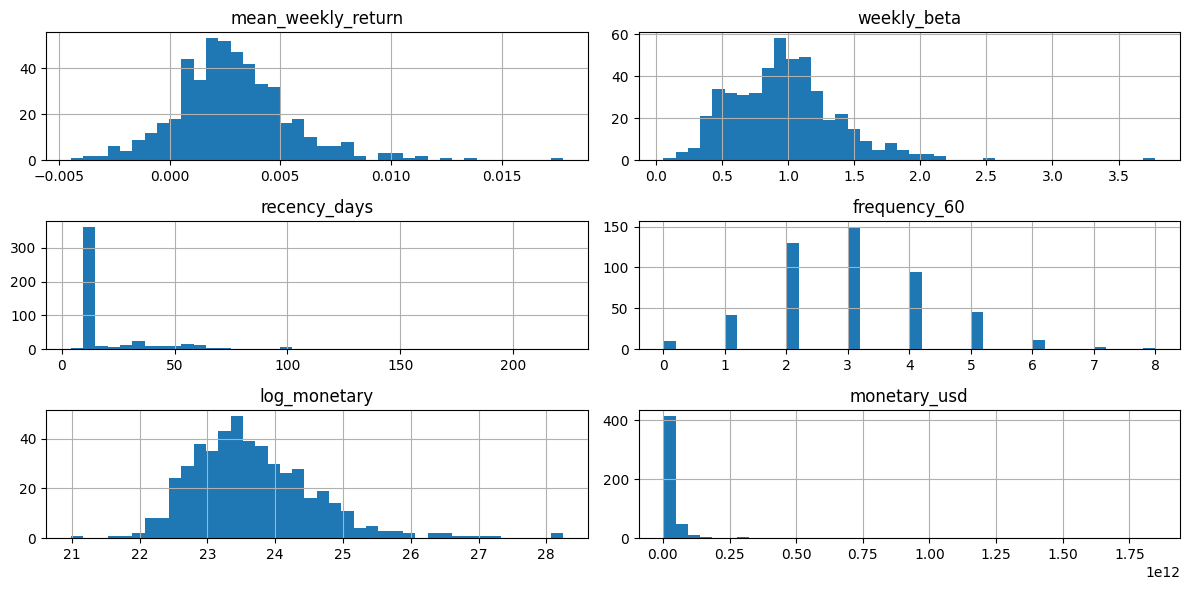

In [59]:
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler

features["log_monetary"] = np.log1p(features["monetary_usd"])
rr_cols = ["mean_weekly_return", "weekly_beta"]
rfm_cols = ["recency_days", "frequency_60", "log_monetary"]

print("Skew (0 = symmetric; above 1 = a long tail to the right):")
print(features[rr_cols + rfm_cols + ["monetary_usd"]].apply(skew).round(2))

z = (features[rr_cols + rfm_cols] - features[rr_cols + rfm_cols].mean()) \
    / features[rr_cols + rfm_cols].std()
print("Shares more than 3 standard deviations from the mean, per feature:")
print((z.abs() > 3).sum())

features[rr_cols + rfm_cols + ["monetary_usd"]].hist(bins=40, figsize=(12, 6))
plt.tight_layout()
plt.savefig("outputs/fig_distributions.png", dpi=150); plt.show()

Z_rr = StandardScaler().fit_transform(features[rr_cols])
Z_rfm = StandardScaler().fit_transform(features[rfm_cols])


**2.2 Agglomerative clustering**

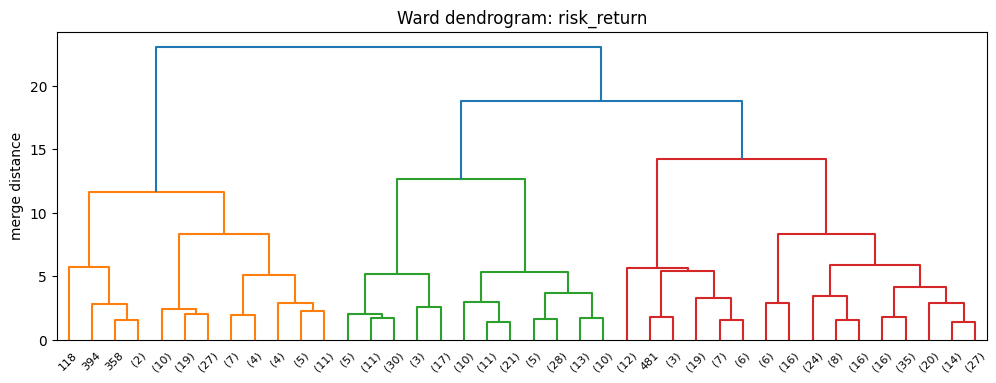

risk_return
   silhouette                             sizes
k                                              
2       0.339                         [394, 92]
3       0.274                    [230, 164, 92]
4       0.282                [182, 164, 92, 48]
5       0.304             [182, 98, 92, 66, 48]
6       0.320          [182, 98, 87, 66, 48, 5]
7       0.324      [160, 98, 87, 66, 48, 22, 5]
8       0.321  [160, 98, 66, 56, 48, 31, 22, 5]


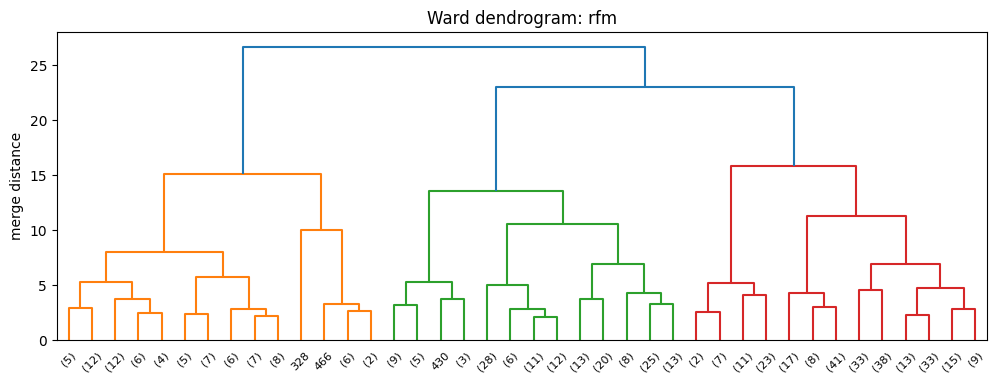

rfm
   silhouette                              sizes
k                                               
2       0.368                          [404, 82]
3       0.304                     [250, 154, 82]
4       0.289                 [207, 154, 82, 43]
5       0.305             [207, 154, 72, 43, 10]
6       0.314         [207, 136, 72, 43, 18, 10]
7       0.292     [141, 136, 72, 66, 43, 18, 10]
8       0.302  [141, 79, 72, 66, 57, 43, 18, 10]


In [60]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

def ward_table(Z):
    rows = []
    for k in range(2, 9):
        model = AgglomerativeClustering(n_clusters=k, linkage="ward")
        labels = model.fit_predict(Z)
        rows.append({"k": k, "silhouette": round(silhouette_score(Z, labels), 3),
                     "sizes": sorted(np.bincount(labels).tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index("k")

for name, Z in [("risk_return", Z_rr), ("rfm", Z_rfm)]:
    plt.figure(figsize=(12, 4))
    dendrogram(linkage(Z, method="ward", metric="euclidean"),
               truncate_mode="lastp", p=40)
    plt.title(f"Ward dendrogram: {name}"); plt.ylabel("merge distance")
    plt.savefig(f"outputs/fig_dendrogram_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(name); print(ward_table(Z))

**2.3 K means clustering**

risk_return
   silhouette  inertia                             sizes
k                                                       
2       0.387    621.6                        [343, 143]
3       0.329    461.2                   [202, 165, 119]
4       0.326    371.6               [160, 153, 132, 41]
5       0.338    310.0           [165, 124, 114, 55, 28]
6       0.326    265.7        [134, 115, 85, 76, 56, 20]
7       0.329    227.2     [126, 105, 84, 78, 47, 41, 5]
8       0.354    194.2  [135, 80, 78, 76, 43, 40, 29, 5]
rfm
   silhouette  inertia                              sizes
k                                                        
2       0.423   1066.8                          [418, 68]
3       0.325    796.6                     [270, 152, 64]
4       0.341    609.8                 [212, 122, 91, 61]
5       0.358    514.7             [198, 122, 87, 68, 11]
6       0.347    437.4        [142, 120, 105, 68, 40, 11]
7       0.349    386.3     [142, 120, 104, 68, 40, 11, 1]
8      

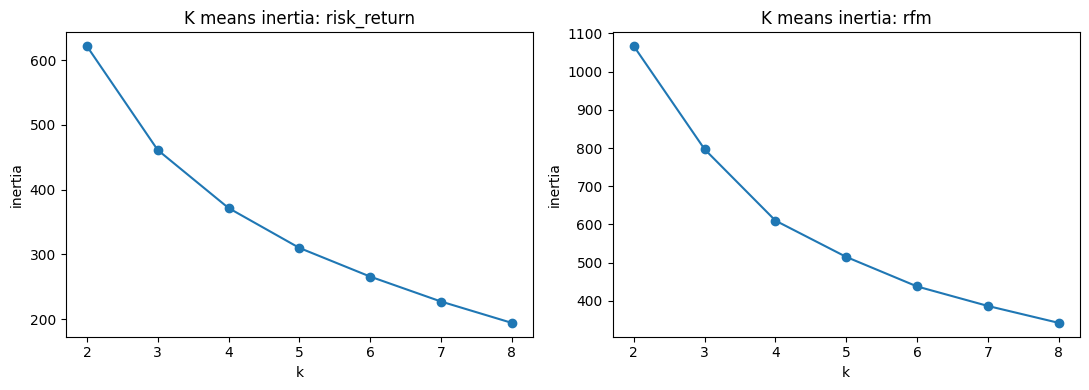

In [61]:
def kmeans_table(Z):
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
        sizes = sorted(np.bincount(km.labels_).tolist(), reverse=True)
        sil = round(silhouette_score(Z, km.labels_), 3)
        rows.append({"k": k, "silhouette": sil,
                     "inertia": round(km.inertia_, 1), "sizes": sizes})
    return pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, Z) in zip(axes, [("risk_return", Z_rr), ("rfm", Z_rfm)]):
    table = kmeans_table(Z)
    print(name); print(table)
    ax.plot(table.index, table["inertia"], marker="o")
    ax.set_title(f"K means inertia: {name}")
    ax.set_xlabel("k"); ax.set_ylabel("inertia")
plt.tight_layout(); plt.savefig("outputs/fig_elbow.png", dpi=150); plt.show()

In [62]:
K_RR, K_RFM = 5, 3

features["rr_ward"] = AgglomerativeClustering(
    n_clusters=K_RR, linkage="ward").fit_predict(Z_rr)
features["rr_kmeans"] = KMeans(
    n_clusters=K_RR, n_init=50, random_state=SEED).fit_predict(Z_rr)
features["rfm_ward"] = AgglomerativeClustering(
    n_clusters=K_RFM, linkage="ward").fit_predict(Z_rfm)
features["rfm_kmeans"] = KMeans(
    n_clusters=K_RFM, n_init=50, random_state=SEED).fit_predict(Z_rfm)
print(features[["rr_ward", "rr_kmeans", "rfm_ward", "rfm_kmeans"]].nunique())

rr_ward       5
rr_kmeans     5
rfm_ward      3
rfm_kmeans    3
dtype: int64


**2.4 Cluster profiles and algorithm comparison**

In [63]:
profile_cols = ["mean_weekly_return", "weekly_beta", "recency_days",
                "frequency_60", "monetary_usd"]
solutions = ["rr_ward", "rr_kmeans", "rfm_ward", "rfm_kmeans"]
for s in solutions:
    profile = features.groupby(s)[profile_cols].mean()
    profile.insert(0, "n_shares", features[s].value_counts())
    print(s); print(profile.round(4)); print()
    profile.to_csv(f"outputs/profile_{s}.csv")

rr_ward
         n_shares  mean_weekly_return  weekly_beta  recency_days  frequency_60  monetary_usd
rr_ward                                                                                     
0              92              0.0063       1.2981       23.6739        3.1957  7.878092e+10
1              48              0.0020       1.6280       23.5417        3.2292  8.693505e+10
2             182              0.0013       0.9728       17.7143        3.0110  1.978763e+10
3              98              0.0042       0.7104       16.9082        2.7041  2.469114e+10
4              66              0.0009       0.4390       26.1970        2.8939  2.588835e+10

rr_kmeans
           n_shares  mean_weekly_return  weekly_beta  recency_days  frequency_60  monetary_usd
rr_kmeans                                                                                     
0               165              0.0043       0.9984       16.8485        2.8970  3.678270e+10
1               114              0.0003      

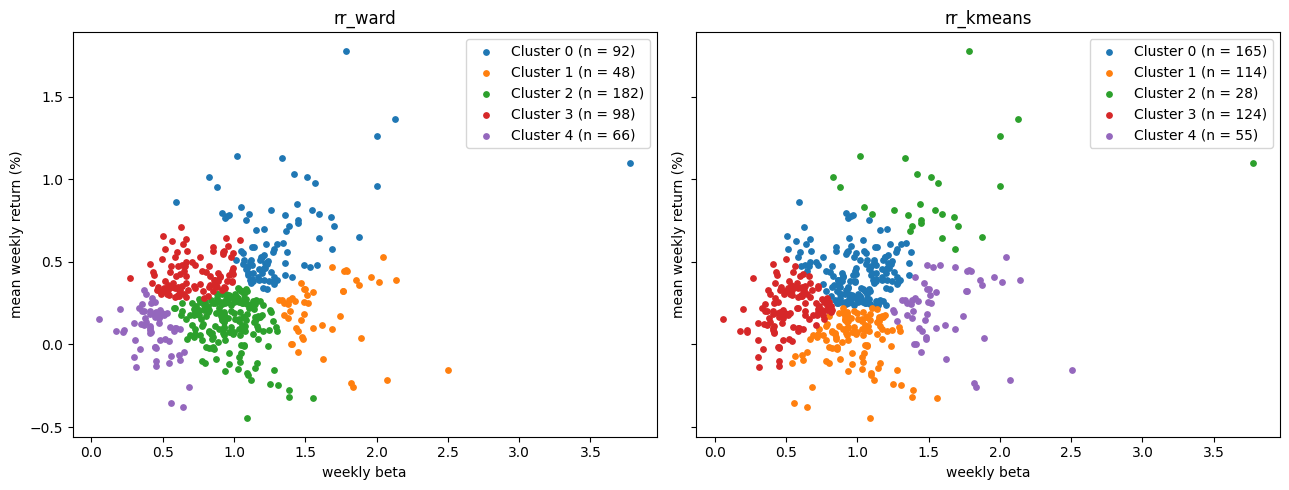

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, s in zip(axes, ["rr_ward", "rr_kmeans"]):
    for c in sorted(features[s].unique()):
        g = features[features[s] == c]
        ax.scatter(g["weekly_beta"], g["mean_weekly_return"] * 100, s=15,
                   label=f"Cluster {c} (n = {len(g)})")
    ax.set_title(s); ax.set_xlabel("weekly beta")
    ax.set_ylabel("mean weekly return (%)"); ax.legend()
plt.tight_layout(); plt.savefig("outputs/fig_rr_clusters.png", dpi=150); plt.show()

Information kept by PC1 and PC2: [0.458 0.336] 0.794


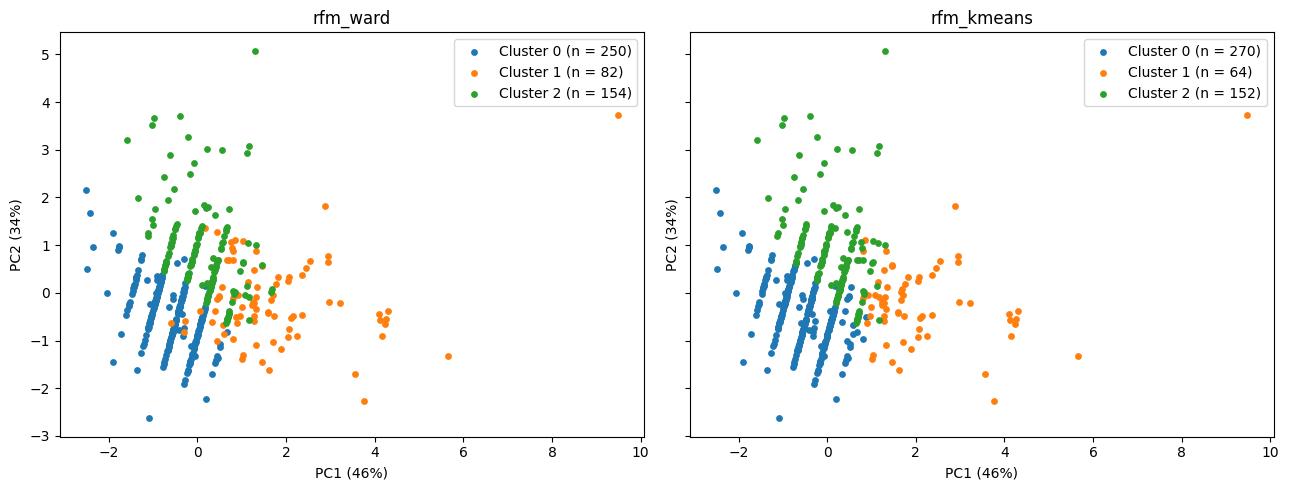

In [65]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit(Z_rfm)
pcs = pca.transform(Z_rfm)
kept = pca.explained_variance_ratio_
print("Information kept by PC1 and PC2:", kept.round(3), kept.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, s in zip(axes, ["rfm_ward", "rfm_kmeans"]):
    for c in sorted(features[s].unique()):
        m = (features[s] == c).to_numpy()
        ax.scatter(pcs[m, 0], pcs[m, 1], s=15, label=f"Cluster {c} (n = {m.sum()})")
    ax.set_title(s); ax.set_xlabel(f"PC1 ({kept[0]:.0%})")
    ax.set_ylabel(f"PC2 ({kept[1]:.0%})"); ax.legend()
plt.tight_layout(); plt.savefig("outputs/fig_rfm_clusters.png", dpi=150); plt.show()

In [66]:
from sklearn.metrics import adjusted_rand_score
for a, b in [("rr_ward", "rr_kmeans"), ("rfm_ward", "rfm_kmeans")]:
    ari = adjusted_rand_score(features[a], features[b])
    print(a, "vs", b, "ARI =", round(ari, 3))
    print(pd.crosstab(features[a], features[b])); print()

rr_ward vs rr_kmeans ARI = 0.329
rr_kmeans   0    1   2   3   4
rr_ward                       
0          60    0  28   0   4
1           0    0   0   0  48
2          49  106   0  24   3
3          56    0   0  42   0
4           0    8   0  58   0

rfm_ward vs rfm_kmeans ARI = 0.834
rfm_kmeans    0   1    2
rfm_ward                
0           250   0    0
1            15  59    8
2             5   5  144



**2.5 RFM sensitivity and correlated inputs**

**2.5.1 Correlation analysis**

In [67]:
print("Pearson correlations among R, F and log1p(M):")
print(features[rfm_cols].corr().round(3))
features[rfm_cols].corr().to_csv("outputs/rfm_correlations.csv")

Pearson correlations among R, F and log1p(M):
              recency_days  frequency_60  log_monetary
recency_days         1.000        -0.346         0.152
frequency_60        -0.346         1.000         0.013
log_monetary         0.152         0.013         1.000


**2.5.2 Removal of Monetary**

In [68]:
Z_rf = StandardScaler().fit_transform(features[["recency_days", "frequency_60"]])
features["rf_only_ward"] = AgglomerativeClustering(
    n_clusters=K_RFM, linkage="ward").fit_predict(Z_rf)

ari = adjusted_rand_score(features["rfm_ward"], features["rf_only_ward"])
print("ARI, with Monetary vs without:", round(ari, 3))
print(pd.crosstab(features["rfm_ward"], features["rf_only_ward"]))
for s in ["rfm_ward", "rf_only_ward"]:
    stats = ["count", "median", "min", "max"]
    summary = features.groupby(s)["monetary_usd"].agg(stats)
    print(s); print((summary / [1, 1e9, 1e9, 1e9]).round(2)); print()

ARI, with Monetary vs without: 0.291
rf_only_ward   0    1   2
rfm_ward                 
0              1  183  66
1             79    3   0
2              9   86  59
rfm_ward
          count  median    min      max
rfm_ward                               
0         250.0   11.18   1.30    37.90
1          82.0   17.85   4.37  1825.34
2         154.0   39.70  18.75  1847.70

rf_only_ward
              count  median   min      max
rf_only_ward                              
0              89.0   20.85  4.37  1825.34
1             272.0   14.86  1.30  1847.70
2             125.0   17.70  3.69   623.30



# Task 3 Business Intelligence and Critical Review

**3.1 Data mart design**

The data mart is a design proposal (grain, facts, dimensions, provenance and stakeholder support) presented in the report with a star schema diagram. No code is required for this subsection. The tables it describes correspond to the files saved by this notebook: daily prices and volumes in `data/`, derived metrics and cluster assignments in `outputs/feature_table.csv`, and run settings in `data/metadata.json`.

**3.2 Review of results and visualisation**

**3.2.1 Cluster profiles and sector composition**

rr_ward - % of each cluster in each sector
sector   Communication Services  Consumer Discretionary  Consumer Staples  Energy  Financials  Health Care  Industrials  Information Technology  Materials  Real Estate  Utilities
rr_ward                                                                                                                                                                           
0                           5.0                    12.0               0.0     4.0        14.0          2.0         23.0                    32.0        3.0          3.0        1.0
1                           0.0                    21.0               0.0     0.0        10.0          8.0          8.0                    48.0        4.0          0.0        0.0
2                           4.0                     9.0               3.0     0.0        14.0         14.0         22.0                    11.0        8.0         13.0        3.0
3                           5.0                     9.0       

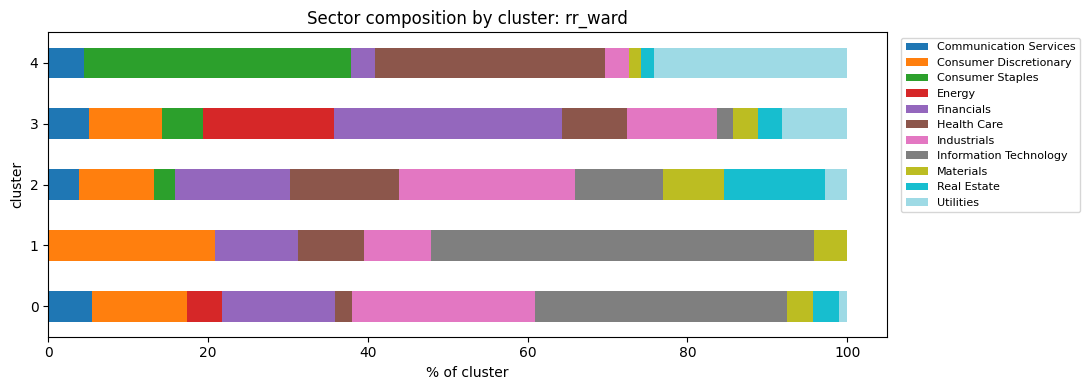

rfm_ward - % of each cluster in each sector
sector    Communication Services  Consumer Discretionary  Consumer Staples  Energy  Financials  Health Care  Industrials  Information Technology  Materials  Real Estate  Utilities
rfm_ward                                                                                                                                                                           
0                            3.0                     7.0               6.0     3.0        16.0         11.0         20.0                    10.0        5.0         11.0        8.0
1                            5.0                    11.0               9.0     2.0        12.0         11.0          7.0                    22.0       10.0          0.0       11.0
2                            6.0                    13.0               7.0     6.0        16.0         14.0         14.0                    20.0        1.0          2.0        1.0



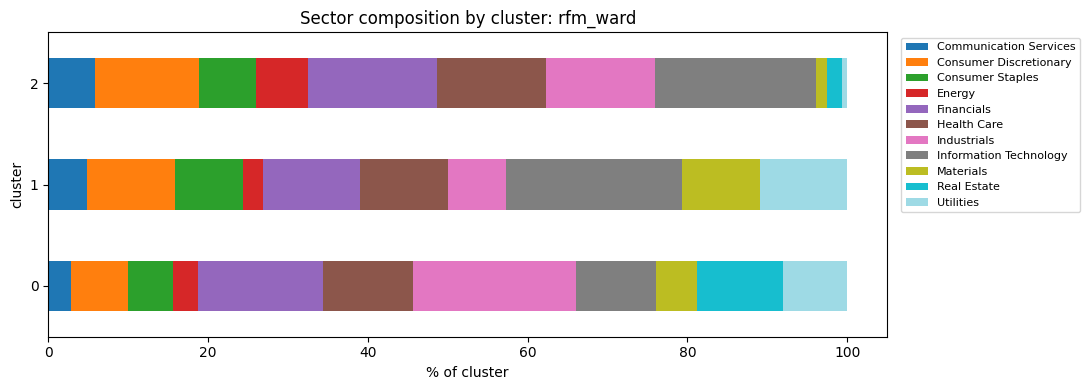

In [69]:
for s in ["rr_ward", "rfm_ward"]:
    pct = pd.crosstab(features[s], features["sector"], normalize="index") * 100
    print(s, "- % of each cluster in each sector"); print(pct.round(0)); print()
    pct.plot(kind="barh", stacked=True, figsize=(11, 4), colormap="tab20")
    plt.xlabel("% of cluster"); plt.ylabel("cluster")
    plt.title(f"Sector composition by cluster: {s}")
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.tight_layout(); plt.savefig(f"outputs/fig_sector_{s}.png", dpi=150); plt.show()

In [70]:
print("Risk-return Ward clusters (rows) vs RFM Ward clusters (columns)")
print(pd.crosstab(features["rr_ward"], features["rfm_ward"]))

Risk-return Ward clusters (rows) vs RFM Ward clusters (columns)
rfm_ward    0   1   2
rr_ward              
0          36  19  37
1          19   9  20
2         115  28  39
3          53  10  35
4          27  16  23


**3.2.2 Sensitivity findings and business uses**

Evidence for this subsection comes from 2.5.1 (correlations among R, F and log1p(M)) and 2.5.2 (removal of Monetary: adjusted Rand index and traded value profiles). The interpretation and business uses are discussed in the report.

**3.2.3 Critical evaluation and limitations**

In [71]:
corr = ret[features.index].corr()
def average_pair_correlation(members):
    block = corr.loc[members, members].to_numpy()
    n = len(block)
    return (block.sum() - n) / (n * (n - 1)) if n > 1 else float("nan")

print("All shares:", round(average_pair_correlation(features.index), 3))
for c, members in features.groupby("rr_ward").groups.items():
    value = average_pair_correlation(members)
    print("Risk-return cluster", c, ":", round(value, 3))

All shares: 0.3
Risk-return cluster 0 : 0.374
Risk-return cluster 1 : 0.438
Risk-return cluster 2 : 0.367
Risk-return cluster 3 : 0.325
Risk-return cluster 4 : 0.312


In [72]:
features.to_csv("outputs/feature_table.csv")
import shutil
shutil.make_archive("data", "zip", "data")
shutil.make_archive("outputs", "zip", "outputs")
try:
    from google.colab import files
    files.download("data.zip"); files.download("outputs.zip")
except ImportError:
    print("Not running in Colab: data.zip and outputs.zip are in the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>